# 05 — Random Forest
A Random Forest (Breiman, 2001) is an ensemble of decision trees. Each tree is grown on a bootstrap
sample of the training data, and at each split only a random subset of features is considered
(`max_features = "sqrt"`). Predictions are averaged across trees. This reduces the high variance of
single trees and lets the model capture **non-linear interactions** without feature scaling.

Settings: `n_estimators = 200`, `random_state = 42`, other parameters at scikit-learn defaults
(fully grown trees, `max_features = "sqrt"`, Gini impurity).

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "electrical_grid_stability.csv"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
%matplotlib inline

In [2]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.preprocessing import FEATURE_COLUMNS, load_and_split_data
from src.train_models import get_random_forest_model
from src.evaluation import evaluate_predictions

X_train, X_test, y_train, y_test = load_and_split_data(DATA_PATH)
rf = get_random_forest_model()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(rf, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True, n_jobs=-1)
pd.DataFrame(cv_res).drop(columns=["fit_time", "score_time"]).agg(["mean", "std"]).round(4)

,test_accuracy,train_accuracy,test_f1_macro,train_f1_macro
mean,0.9162,1.0,0.9078,1.0
std,0.0122,0.0,0.0132,0.0


In [3]:
rf.fit(X_train, y_train)
print("Training accuracy:", accuracy_score(y_train, rf.predict(X_train)))
res = evaluate_predictions(y_test, rf.predict(X_test))
print("Test accuracy:", round(res["accuracy"], 4))
print(res["classification_report"])
print("Confusion matrix (order: stable, unstable)")
print(res["confusion_matrix"])

Training accuracy: 1.0


Test accuracy: 0.929
              precision    recall  f1-score   support

      stable     0.9292    0.8702    0.8987       724
    unstable     0.9289    0.9624    0.9453      1276

    accuracy                         0.9290      2000
   macro avg     0.9290    0.9163    0.9220      2000
weighted avg     0.9290    0.9290    0.9285      2000

Confusion matrix (order: stable, unstable)
[[ 630   94]
 [  48 1228]]


**Interpretation:**
- Test accuracy is **92.9%** and unstable recall 96.2% — only 48 missed instabilities vs 146 for
  Logistic Regression.
- Training accuracy is **100%** while CV/test accuracy is ≈ 92–93%. Fully grown trees memorise the
  training data; the forest still generalises well because averaging cancels much of that variance,
  but the 7-point gap shows overfitting. Notebook 07 tests depth and leaf-size limits.

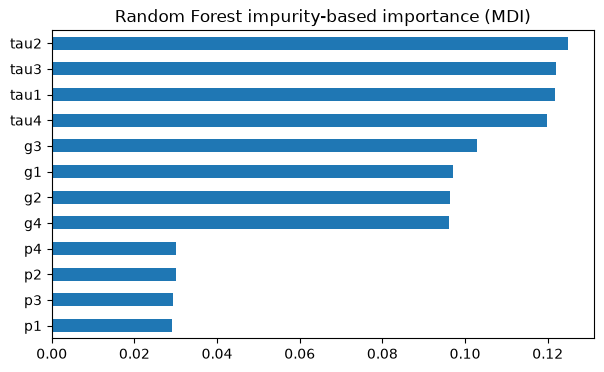

tau2    0.1250
tau3    0.1221
tau1    0.1218
tau4    0.1198
g3      0.1028
g1      0.0971
g2      0.0964
g4      0.0960
p4      0.0302
p2      0.0301
p3      0.0294
p1      0.0292
dtype: float64

In [4]:
mdi = pd.Series(rf.feature_importances_, index=FEATURE_COLUMNS).sort_values()
mdi.plot.barh(figsize=(7, 4), title="Random Forest impurity-based importance (MDI)")
plt.show()
mdi.sort_values(ascending=False).round(4)

**Interpretation:** reaction times `tau1`–`tau4` (≈ 0.12 each) and elasticities `g1`–`g4` (≈ 0.10 each)
dominate, while power values contribute ≈ 0.03 each. MDI can overstate continuous, high-cardinality
features, so notebook 07 confirms the ranking with permutation importance on the test set.